In [ ]:
!nvidia-smi    # should show a GPU (e.g. Tesla T4). If error: GPU is not enabled.
from google.colab import drive
drive.mount('/content/drive')

Thu Oct  8 16:23:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os, random, time, copy, glob, shutil
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import CosineAnnealingLR
from torchvision import transforms, models
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = '/content/drive/MyDrive/glaucoma'
RAW  = f'{ROOT}/raw'
DATA = f'{ROOT}/data'
OUT  = f'{ROOT}/results'
os.makedirs(DATA, exist_ok=True); os.makedirs(OUT, exist_ok=True)
IMG, BATCH, EPOCHS, LR, SEED = 224, 32, 15, 1e-4, 123   # SAME for every model (fair comparison)
# SEED is 42 for the first run; later set SEED = 7, then SEED = 123 and re-run the Day 4 cell
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = (DEVICE == 'cuda')                            # mixed precision = faster training
print('Using device:', DEVICE)
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

Using device: cuda


In [ ]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp')
def sort_by_rule(src_folder, dataset_name, is_glaucoma):
    '''Copy every image from src_folder into data/dataset_name/{glaucoma|normal}.
    is_glaucoma is a function: file name -> True/False.'''
    n = 0
    for f in os.listdir(src_folder):
        if not f.lower().endswith(IMG_EXT): continue
        cls = 'glaucoma' if is_glaucoma(f) else 'normal'
        dst = f'{DATA}/{dataset_name}/{cls}'
        os.makedirs(dst, exist_ok=True)
        shutil.copy(f'{src_folder}/{f}', f'{dst}/{f}')
        n += 1
    print(dataset_name, 'copied', n, 'images')

In [ ]:
print(os.listdir(RAW))                        # see what you have
print(os.listdir(f'{RAW}/ACRIMA')[:10])       # peek at file names to understand the label rule
# ACRIMA: glaucoma files contain '_g_' in the name (CHECK by printing names first!)
sort_by_rule(f'{RAW}/ACRIMA', 'ACRIMA', lambda f: '_g_' in f.lower())
# G1020: labels in a CSV. Look at the columns first, names may differ in your copy.
lab = pd.read_csv(f'{RAW}/G1020/G1020.csv')
print(lab.head())
g_set = set(lab.loc[lab['binaryLabels'] == 1, 'imageID'])   # edit column names if needed
sort_by_rule(f'{RAW}/G1020/Images', 'G1020',
             lambda f: (f in g_set) or (os.path.splitext(f)[0] in g_set))
# RIM-ONE DL: if it already has 'glaucoma' and 'normal' folders, just copy them:
shutil.copytree(f'{RAW}/RIM-ONE DL/glaucoma', f'{DATA}/RIM-ONE_DL/glaucoma', dirs_exist_ok=True)
shutil.copytree(f'{RAW}/RIM-ONE DL/normal',   f'{DATA}/RIM-ONE_DL/normal',   dirs_exist_ok=True)

['ACRIMA', 'RIM-ONE DL', 'ORIGA', 'G1020']
['Im132_ACRIMA.jpg', 'Im232_ACRIMA.jpg', 'Im086_ACRIMA.jpg', 'Im154_ACRIMA.jpg', 'Im236_ACRIMA.jpg', 'Im099_ACRIMA.jpg', 'Im169_ACRIMA.jpg', 'Im349_g_ACRIMA.jpg', 'Im078_ACRIMA.jpg', 'Im068_ACRIMA.jpg']
ACRIMA copied 705 images
       imageID  binaryLabels
0  image_0.jpg             0
1  image_1.jpg             0
2  image_3.jpg             0
3  image_4.jpg             0
4  image_5.jpg             0


In [ ]:
# ORIGA: labels in OrigaList.csv (column 'Glaucoma': 1 = glaucoma), images in Images_Cropped
lab = pd.read_csv(f'{RAW}/ORIGA/OrigaList.csv')
print('Columns:', lab.columns.tolist())   # check that 'Filename' and 'Glaucoma' really exist
print(lab.head())
# Collect glaucoma file names. Keep both the full name (001.jpg) and the name without
# extension (001), so the match works even if the CSV and the image folder differ in extension.
g_names = lab.loc[lab['Glaucoma'] == 1, 'Filename'].astype(str).str.strip()
g_set = set(g_names) | {os.path.splitext(n)[0] for n in g_names}
sort_by_rule(f'{RAW}/ORIGA/Images', 'ORIGA',
             lambda f: (f in g_set) or (os.path.splitext(f)[0] in g_set))
# quick check: expect about 168 glaucoma and 482 normal
for c in ['glaucoma', 'normal']:
    print('ORIGA', c, len(os.listdir(f'{DATA}/ORIGA/{c}')))

Columns: ['Eye', 'Filename', 'ExpCDR', 'Set', 'Glaucoma']
  Eye Filename  ExpCDR Set  Glaucoma
0  OD  001.jpg  0.7097   A         0
1  OS  002.jpg  0.6953   A         0
2  OS  003.jpg  0.9629   A         0
3  OD  004.jpg  0.7246   A         0
4  OS  005.jpg  0.6138   A         0
ORIGA copied 650 images
ORIGA glaucoma 168
ORIGA normal 482


In [ ]:
rows = []
for ds in sorted(os.listdir(DATA)):
    for cls, label in [('normal', 0), ('glaucoma', 1)]:
        folder = f'{DATA}/{ds}/{cls}'
        if not os.path.isdir(folder): continue
        for f in os.listdir(folder):
            if f.lower().endswith(IMG_EXT):
                rows.append(dict(path=f'{folder}/{f}', label=label, dataset=ds))
df = pd.DataFrame(rows)
df.to_csv(f'{ROOT}/master.csv', index=False)
print(df.groupby(['dataset', 'label']).size().unstack())

label         0    1
dataset             
ACRIMA      309  396
G1020       724  296
ORIGA       482  168
RIM-ONE_DL  313  172


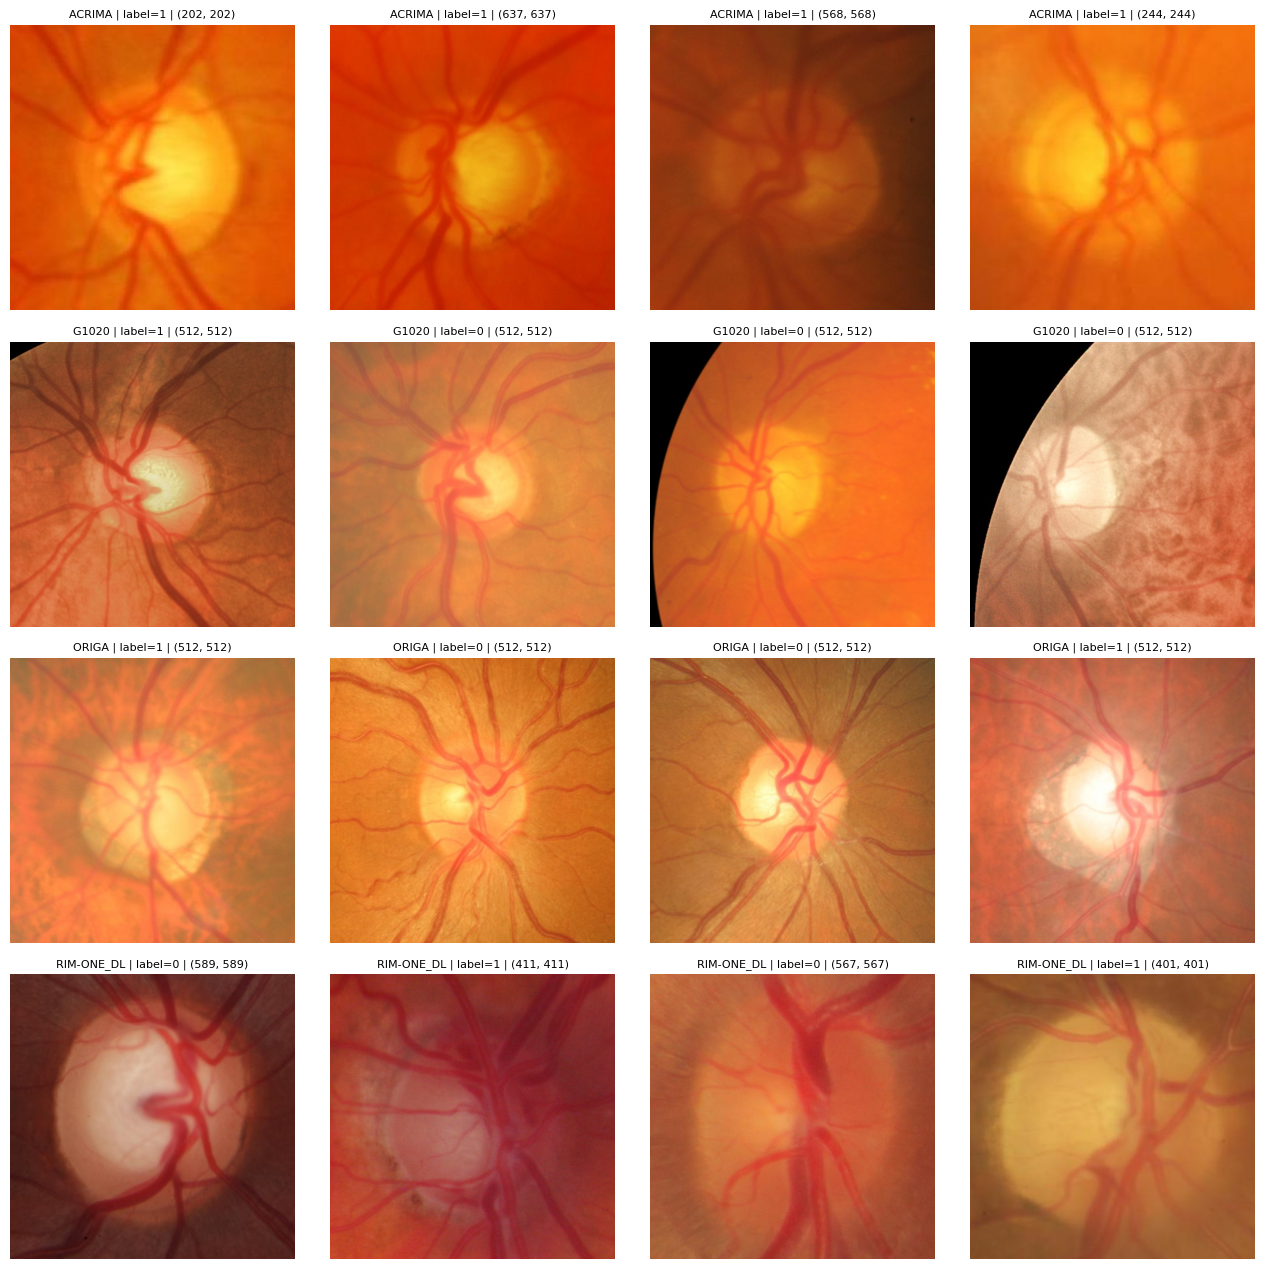

In [ ]:
names = sorted(df.dataset.unique())
fig, axes = plt.subplots(len(names), 4, figsize=(13, 3.2 * len(names)))
for i, ds in enumerate(names):
    sample = df[df.dataset == ds].sample(4, random_state=0)
    for j, (_, r) in enumerate(sample.iterrows()):
        im = Image.open(r.path)
        axes[i, j].imshow(im); axes[i, j].axis('off')
        axes[i, j].set_title(f"{ds} | label={r.label} | {im.size}", fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUT}/sample_images.png', dpi=120); plt.show()

In [ ]:
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])   # ImageNet statistics
train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15), transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(), norm])
eval_tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), norm])
class FundusDS(Dataset):
    def __init__(self, frame, tf):
        self.paths = frame.path.tolist()
        self.labels = frame.label.values.astype('float32')
        self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.tf(img), torch.tensor(self.labels[i])

In [ ]:
def split_source(d, seed):
    trval, te = train_test_split(d, test_size=0.15, stratify=d.label, random_state=seed)
    tr, va = train_test_split(trval, test_size=0.15 / 0.85, stratify=trval.label, random_state=seed)
    return tr, va, te
# quick check
d = df[df.dataset == df.dataset.unique()[0]]
tr, va, te = split_source(d, SEED)
print(len(tr), len(va), len(te), '| glaucoma ratio:',
      tr.label.mean().round(2), va.label.mean().round(2), te.label.mean().round(2))

493 106 106 | glaucoma ratio: 0.56 0.56 0.57


In [ ]:
def make_model(name):
    if name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, 1)
    elif name == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Linear(m.classifier.in_features, 1)
    elif name == 'mobilenet_v2':
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'efficientnet_b0':
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 1)
    elif name == 'inception_v3':
        m = models.inception_v3(weights=models.Inception_V3_Weights.IMAGENET1K_V1)
        m.aux_logits = False; m.AuxLogits = None   # turn off the auxiliary head (simplifies training)
        m.fc = nn.Linear(m.fc.in_features, 1)
    else:
        raise ValueError(name)
    return m.to(DEVICE)
print(sum(p.numel() for p in make_model('mobilenet_v2').parameters()) / 1e6, 'million parameters')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 144MB/s]


2.225153 million parameters


In [ ]:
def predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x)
            ps.append(torch.sigmoid(out.float()).squeeze(1).cpu().numpy())
            ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)
def metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(auc=roc_auc_score(y, p),
                sens=tp / max(tp + fn, 1), spec=tn / max(tn + fp, 1),
                acc=(tp + tn) / len(y))
def make_loader(frame, tf, shuffle=False, drop_last=False):
    return DataLoader(FundusDS(frame, tf), batch_size=BATCH, shuffle=shuffle,
                      num_workers=2, drop_last=drop_last)

In [ ]:
def train_model(name, tr, va, seed, epochs=EPOCHS, patience=5):
    seed_everything(seed)
    model = make_model(name)
    tl = make_loader(tr, train_tf, shuffle=True, drop_last=True)
    vl = make_loader(va, eval_tf)
    pos = float(tr.label.sum()); neg = len(tr) - pos
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([neg / pos], device=DEVICE))
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    best_auc, best_state, bad = -1.0, None, 0
    for ep in range(epochs):
        model.train(); tot = 0.0
        for x, y in tl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
                out = model(x).squeeze(1)
            loss = crit(out.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(x)
        sched.step()
        yv, pv = predict(model, vl)
        auc = roc_auc_score(yv, pv)
        print(f'  [{name}] epoch {ep+1:02d}  train_loss {tot/len(tr):.3f}  val_auc {auc:.3f}')
        if auc > best_auc:
            best_auc, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    yv, pv = predict(model, vl)
    fpr, tpr, th = roc_curve(yv, pv)
    thr = float(th[np.argmax(tpr - fpr)])
    return model, thr, float(best_auc)

In [ ]:
name_ds = 'ACRIMA'                 # must match a folder name in data/
d = df[df.dataset == name_ds]
tr, va, te = split_source(d, SEED)
model, thr, val_auc = train_model('mobilenet_v2', tr, va, SEED)
y, p = predict(model, make_loader(te, eval_tf))
print('threshold', round(thr, 3), '| in-domain test:',
      {k: round(v, 3) for k, v in metrics(y, p, thr).items()})
other = [n for n in df.dataset.unique() if n != name_ds][0]
y, p = predict(model, make_loader(df[df.dataset == other], eval_tf))
print('cross-domain on', other, {k: round(v, 3) for k, v in metrics(y, p, thr).items()})

  [mobilenet_v2] epoch 01  train_loss 0.311  val_auc 0.997
  [mobilenet_v2] epoch 02  train_loss 0.092  val_auc 0.999
  [mobilenet_v2] epoch 03  train_loss 0.086  val_auc 0.999
  [mobilenet_v2] epoch 04  train_loss 0.030  val_auc 1.000
  [mobilenet_v2] epoch 05  train_loss 0.037  val_auc 0.999
  [mobilenet_v2] epoch 06  train_loss 0.038  val_auc 0.999
  [mobilenet_v2] epoch 07  train_loss 0.017  val_auc 0.999
  [mobilenet_v2] epoch 08  train_loss 0.029  val_auc 0.999
  [mobilenet_v2] epoch 09  train_loss 0.023  val_auc 0.999
threshold 0.842 | in-domain test: {'auc': np.float64(1.0), 'sens': np.float64(0.983), 'spec': np.float64(0.978), 'acc': np.float64(0.981)}
cross-domain on G1020 {'auc': np.float64(0.477), 'sens': np.float64(0.736), 'spec': np.float64(0.196), 'acc': np.float64(0.353)}


In [ ]:
MODELS  = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
SOURCES = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']   # training sources (G1020 is NOT a source)
TARGETS = SOURCES + ['G1020']                  # G1020 = external test-only target
assert set(TARGETS) <= set(df.dataset.unique()), 'a dataset folder is missing from master.csv'
res_file = f'{OUT}/results_seed{SEED}.csv'
results = pd.read_csv(res_file).to_dict('records') if os.path.exists(res_file) else []
done = {(r['model'], r['source']) for r in results}
for src in SOURCES:
    tr, va, te = split_source(df[df.dataset == src], SEED)
    for name in MODELS:
        if (name, src) in done: continue
        t0 = time.time()
        print(f'=== train {name} on {src} (train={len(tr)}, val={len(va)}, test={len(te)}) ===')
        model, thr, val_auc = train_model(name, tr, va, SEED)
        for tgt in TARGETS:
            d_eval = te if tgt == src else df[df.dataset == tgt]
            y, p = predict(model, make_loader(d_eval, eval_tf))
            m = metrics(y, p, thr)
            results.append(dict(seed=SEED, model=name, source=src, target=tgt,
                                setting='in-domain' if tgt == src else 'cross-domain',
                                n=len(d_eval), val_auc=val_auc, thr=thr, **m))
            print(f'  -> test on {tgt:12s} AUC {m["auc"]:.3f} sens {m["sens"]:.2f} spec {m["spec"]:.2f}')
        pd.DataFrame(results).to_csv(res_file, index=False)    # save after every run
        del model; torch.cuda.empty_cache()
        print(f'  done in {(time.time()-t0)/60:.1f} min\n')

=== train resnet50 on ACRIMA (train=493, val=106, test=106) ===
  [resnet50] epoch 01  train_loss 0.487  val_auc 0.849
  [resnet50] epoch 02  train_loss 0.223  val_auc 0.992
  [resnet50] epoch 03  train_loss 0.109  val_auc 0.994
  [resnet50] epoch 04  train_loss 0.063  val_auc 0.991
  [resnet50] epoch 05  train_loss 0.052  val_auc 0.997
  [resnet50] epoch 06  train_loss 0.030  val_auc 0.992
  [resnet50] epoch 07  train_loss 0.020  val_auc 1.000
  [resnet50] epoch 08  train_loss 0.026  val_auc 1.000
  [resnet50] epoch 09  train_loss 0.037  val_auc 1.000
  [resnet50] epoch 10  train_loss 0.028  val_auc 1.000
  [resnet50] epoch 11  train_loss 0.016  val_auc 1.000
  [resnet50] epoch 12  train_loss 0.015  val_auc 1.000
  [resnet50] epoch 13  train_loss 0.015  val_auc 1.000
  -> test on ACRIMA       AUC 1.000 sens 0.97 spec 1.00
  -> test on ORIGA        AUC 0.682 sens 0.60 spec 0.68
  -> test on RIM-ONE_DL   AUC 0.645 sens 0.87 spec 0.31
  -> test on G1020        AUC 0.478 sens 0.69 spec 0.

In [ ]:
r = pd.read_csv(f'{OUT}/results_seed{SEED}.csv')
print(len(r), r.seed.unique())   # expect 60 and [42] (or [7], [123])


60 [123]


In [ ]:
shutil.copy(f'{OUT}/results_seed{SEED}.csv', f'{OUT}/backup_results_seed{SEED}.csv')

'/content/drive/MyDrive/glaucoma/results/backup_results_seed123.csv'

files loaded: {42: 60, 7: 60, 123: 60} rows per seed
primary rows 135 | external rows 45 | ignored rows with G1020 as SOURCE 0 (should be 0; G1020 is test-only)
completeness OK: 3 seeds x 5 models x (9 primary + 3 G1020) results present
saved primary_3x3_auc_mean_sd.csv (45, 8)
saved primary_sens_spec_mean_sd.csv (45, 17)

PRIMARY train/test performance (3 seeds)
          Model     Source     Target      Setting AUC Mean ± SD Sensitivity Mean ± SD Specificity Mean ± SD Accuracy Mean ± SD
       ResNet50     ACRIMA     ACRIMA    in-domain 0.997 ± 0.005         0.967 ± 0.017         0.986 ± 0.025      0.975 ± 0.020
       ResNet50     ACRIMA      ORIGA cross-source 0.642 ± 0.035         0.692 ± 0.179         0.507 ± 0.213      0.555 ± 0.114
       ResNet50     ACRIMA RIM-ONE DL cross-source 0.567 ± 0.069         0.901 ± 0.035         0.194 ± 0.101      0.445 ± 0.055
       ResNet50      ORIGA     ACRIMA cross-source 0.734 ± 0.050         0.707 ± 0.115         0.585 ± 0.275      0.653 ± 

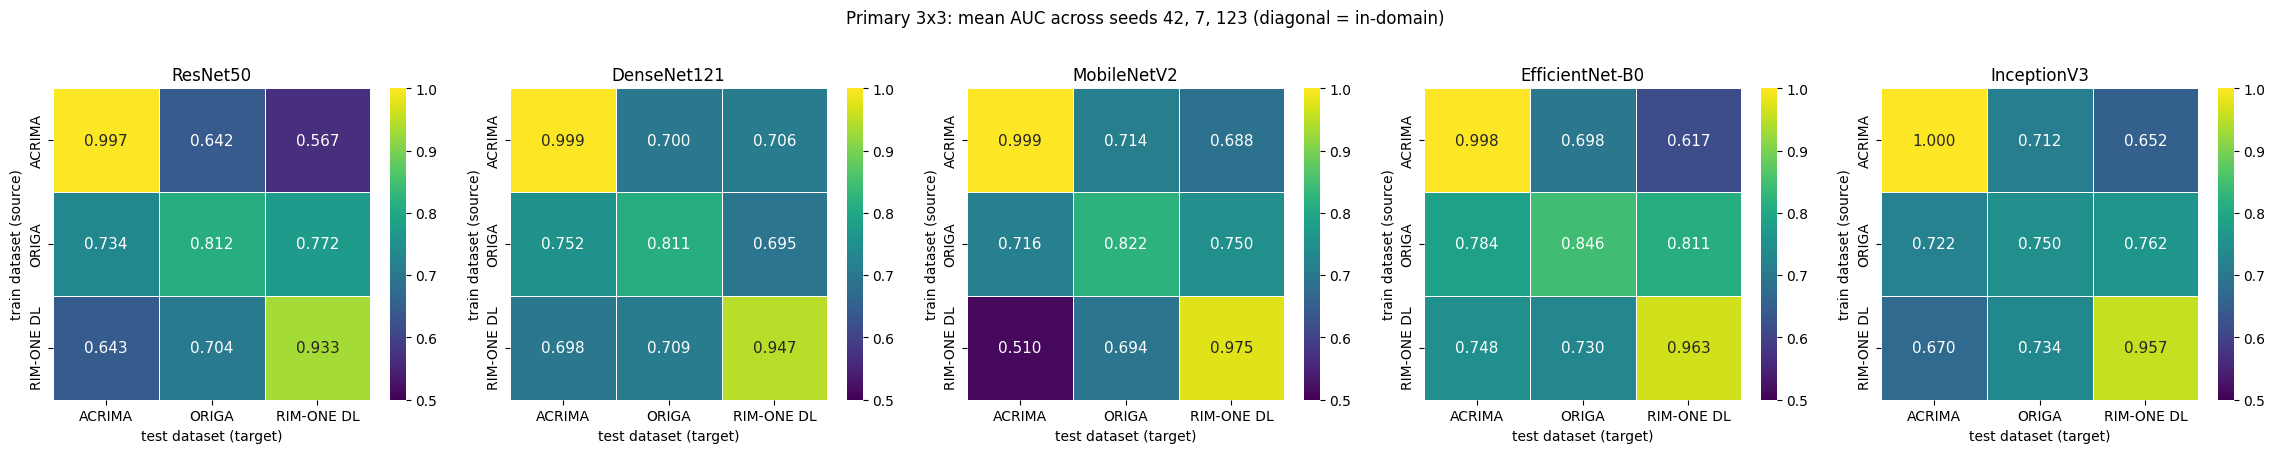

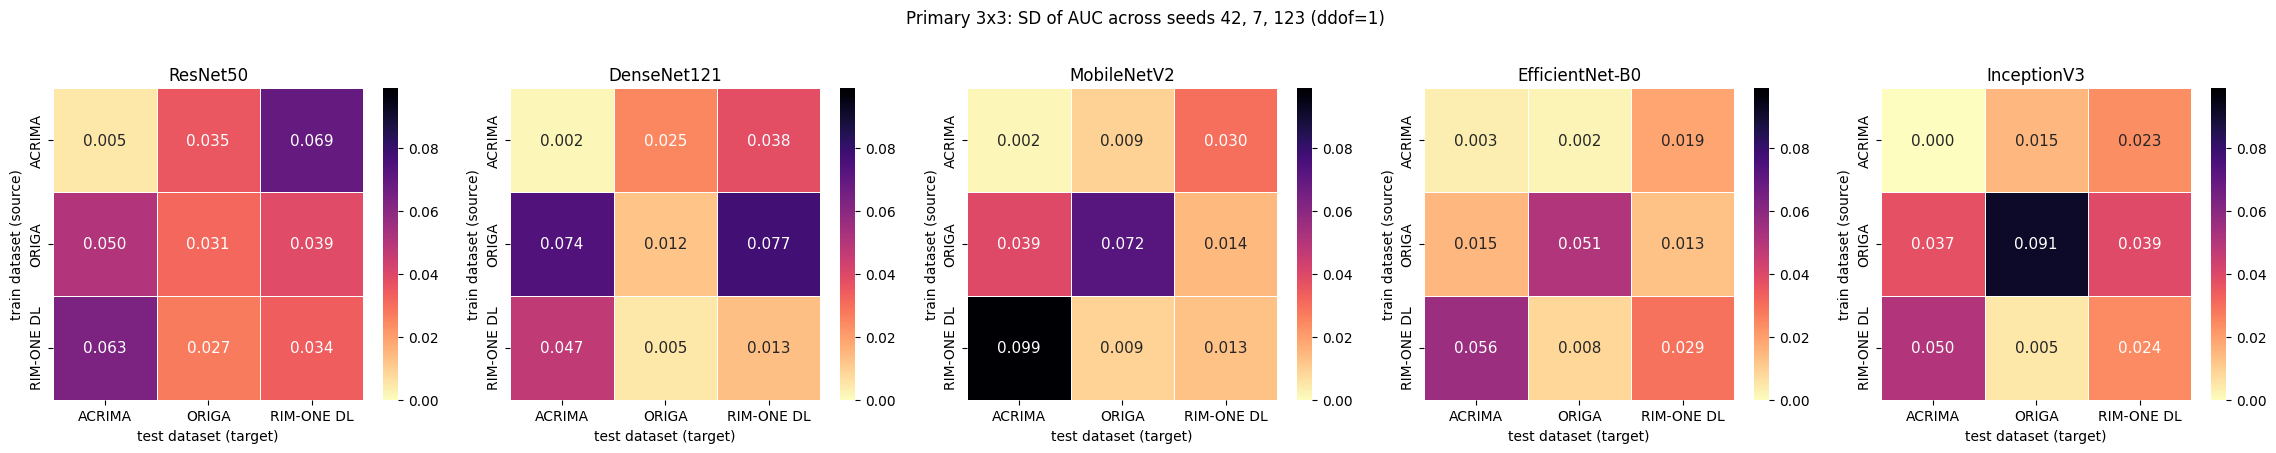

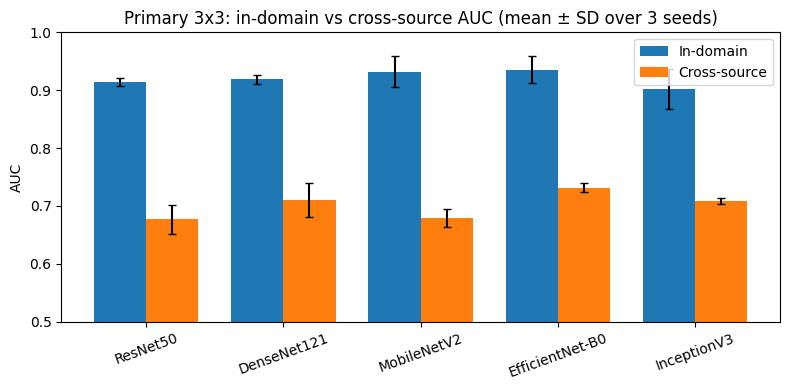

In [ ]:
# ===== Step 5 (REVISED): results, reporting and statistical analysis =====
# Needs only: OUT (from Step 2.1). Reads ONLY the three seed files. Trains nothing.
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from itertools import product
# ---- 5.0  Fixed definitions (nothing here changes the experiment) -------------------
EXPECTED_SEEDS = [42, 7, 123]
SEED_FILES = {s: f'{OUT}/results_seed{s}.csv' for s in EXPECTED_SEEDS}   # no glob
REQ_COLS = ['seed', 'model', 'source', 'target', 'setting', 'n', 'val_auc', 'thr',
            'auc', 'sens', 'spec', 'acc']
MODELS   = ['resnet50', 'densenet121', 'mobilenet_v2', 'efficientnet_b0', 'inception_v3']
PRIMARY  = ['ACRIMA', 'ORIGA', 'RIM-ONE_DL']      # folder names used in data/
EXTERNAL = 'G1020'                                # test-only external dataset
METRICS  = ['auc', 'sens', 'spec', 'acc']
LABEL = {'ACRIMA': 'ACRIMA', 'ORIGA': 'ORIGA', 'RIM-ONE_DL': 'RIM-ONE DL', 'G1020': 'G1020',
         'resnet50': 'ResNet50', 'densenet121': 'DenseNet121', 'mobilenet_v2': 'MobileNetV2',
         'efficientnet_b0': 'EfficientNet-B0', 'inception_v3': 'InceptionV3'}
RANK = {k: i for i, k in enumerate(MODELS + PRIMARY + [EXTERNAL] + ['in-domain', 'cross-source'])}
def check(cond, msg):
    if not cond: raise ValueError('REPORTING CHECK FAILED: ' + msg)
def pm(m, s, d=3):                         # "0.912 ± 0.021"
    return f'{m:.{d}f} ± {s:.{d}f}'
def sort_rows(df):
    cols = [c for c in ['model', 'source', 'target', 'setting'] if c in df.columns]
    return df.sort_values(cols, key=lambda s: s.map(RANK)).reset_index(drop=True)
def save(df, name):
    df.to_csv(f'{OUT}/{name}', index=False, encoding='utf-8-sig')
    print('saved', name, df.shape)
def summarize(df, keys, cols=METRICS):
    """mean and sample SD (ddof=1) ACROSS SEEDS. Every group must hold exactly one row per seed,
    so no image-level or repeated-row averaging can happen."""
    g = df.groupby(keys, sort=False)
    out = g[cols].mean().add_suffix('_mean').join(g[cols].std(ddof=1).add_suffix('_sd'))
    out['n_seeds'] = g['seed'].nunique()
    check((out.n_seeds == len(EXPECTED_SEEDS)).all(), f'{keys}: a group does not have all 3 seeds')
    check((g.size() == out.n_seeds).all(), f'{keys}: more than one row per seed in a group')
    for c in cols:
        out[f'{c}_mean_sd'] = [pm(m, s) for m, s in zip(out[f'{c}_mean'], out[f'{c}_sd'])]
    return out.reset_index()
# ---- 5.1  Load ONLY the three expected files and validate them ----------------------
frames = []
for s, f in SEED_FILES.items():
    if not os.path.isfile(f): raise FileNotFoundError(f'Missing results file for seed {s}: {f}')
    try: d = pd.read_csv(f)
    except Exception as e: raise RuntimeError(f'Cannot read {f}: {e}')
    absent = [c for c in REQ_COLS if c not in d.columns]
    check(not absent, f'{f}: missing columns {absent}')
    check(len(d) > 0, f'{f} is empty')
    found = sorted(d['seed'].unique().tolist())
    check(found == [s], f'{f}: expected seed [{s}] but file contains {found}')
    frames.append(d[REQ_COLS].copy())
allr = pd.concat(frames, ignore_index=True)
for c in ['model', 'source', 'target', 'setting']:
    allr[c] = allr[c].astype(str).str.strip()
check(sorted(allr.seed.unique().tolist()) == sorted(EXPECTED_SEEDS), 'seed set is not {42, 7, 123}')
check(set(allr.model) <= set(MODELS), f'unknown models: {set(allr.model) - set(MODELS)}')
check((set(allr.source) | set(allr.target)) <= set(PRIMARY + [EXTERNAL]),
      f'unknown datasets: {(set(allr.source) | set(allr.target)) - set(PRIMARY + [EXTERNAL])}')
dups = allr[allr.duplicated(['seed', 'model', 'source', 'target'], keep=False)]
check(len(dups) == 0, f'duplicate (seed, model, source, target) rows:\n{dups}')
exp_set = np.where(allr.source == allr.target, 'in-domain', 'cross-domain')
check((allr.setting.values == exp_set).all(), "'setting' disagrees with source == target")
print('files loaded:', {s: int((allr.seed == s).sum()) for s in EXPECTED_SEEDS}, 'rows per seed')
# ---- 5.2  Scope split: PRIMARY 3x3 vs EXTERNAL G1020 (they can never mix) -----------
prim = allr[allr.source.isin(PRIMARY) & allr.target.isin(PRIMARY)].copy()
ext  = allr[allr.source.isin(PRIMARY) & (allr.target == EXTERNAL)].copy()
rest = allr.drop(index=prim.index.union(ext.index))
check(rest.source.eq(EXTERNAL).all(), 'unexpected rows outside primary/external scope')
check(~prim.source.eq(EXTERNAL).any() and ~prim.target.eq(EXTERNAL).any(), 'G1020 leaked into primary')
check(ext.target.eq(EXTERNAL).all() and ext.source.isin(PRIMARY).all(), 'external table is malformed')
print(f'primary rows {len(prim)} | external rows {len(ext)} | '
      f'ignored rows with G1020 as SOURCE {len(rest)} (should be 0; G1020 is test-only)')
# ---- 5.3  Missing-result detection (never silently ignored) -------------------------
expected = pd.DataFrame(list(product(EXPECTED_SEEDS, MODELS, PRIMARY, PRIMARY + [EXTERNAL])),
                        columns=['seed', 'model', 'source', 'target'])
chk = expected.merge(allr[['seed', 'model', 'source', 'target']], how='left', indicator=True)
missing = chk[chk['_merge'] == 'left_only'].drop(columns='_merge')
if len(missing):
    missing['setting'] = np.where(missing.source == missing.target, 'in-domain', 'cross-domain')
    print(missing[['model', 'source', 'target', 'setting', 'seed']].to_string(index=False))
    raise ValueError(f'{len(missing)} required result(s) missing (listed above): '
                     'finish those runs before reporting.')
for d_ in (prim, ext):
    d_[METRICS] = d_[METRICS].apply(pd.to_numeric, errors='raise').astype(float)
    check(d_[METRICS].notna().all().all(), 'NaN found in auc/sens/spec/acc')
check(len(prim) == 3 * 5 * 9 and len(ext) == 3 * 5 * 3, 'unexpected number of result rows')
print('completeness OK: 3 seeds x 5 models x (9 primary + 3 G1020) results present')
# ---- 5.4  PRIMARY 3x3: per-cell mean and SD across seeds ----------------------------
cell = sort_rows(summarize(prim, ['model', 'source', 'target']))
cell.insert(3, 'setting', np.where(cell.source == cell.target, 'in-domain', 'cross-source'))
save(cell[['model', 'source', 'target', 'setting', 'n_seeds',
           'auc_mean', 'auc_sd', 'auc_mean_sd']], 'primary_3x3_auc_mean_sd.csv')
save(cell[['model', 'source', 'target', 'setting', 'n_seeds'] +
          [f'{m}_{k}' for m in METRICS for k in ('mean', 'sd', 'mean_sd')]],
     'primary_sens_spec_mean_sd.csv')          # per-cell AUC, sens, spec, acc
# detailed train/test table (display version)
detail = cell[['model', 'source', 'target', 'setting', 'auc_mean_sd',
               'sens_mean_sd', 'spec_mean_sd', 'acc_mean_sd']].copy()
for c in ['model', 'source', 'target']: detail[c] = detail[c].map(LABEL)
detail.columns = ['Model', 'Source', 'Target', 'Setting', 'AUC Mean ± SD',
                  'Sensitivity Mean ± SD', 'Specificity Mean ± SD', 'Accuracy Mean ± SD']
print('\nPRIMARY train/test performance (3 seeds)'); print(detail.to_string(index=False))
# ---- 5.5  PRIMARY AUC DROP: seed-level FIRST, aggregate afterwards ------------------
lvl = prim.groupby(['model', 'seed', 'setting'], as_index=False)[METRICS].mean()
cnt = prim.groupby(['model', 'seed', 'setting']).size().unstack('setting')
check((cnt['in-domain'] == 3).all() and (cnt['cross-domain'] == 6).all(),
      'need 3 diagonal and 6 off-diagonal cells per model and seed')
wide = lvl.pivot(index=['model', 'seed'], columns='setting', values='auc').reset_index()
wide = wide.rename(columns={'in-domain': 'in_domain_auc', 'cross-domain': 'cross_source_auc'})
wide['auc_drop'] = wide.in_domain_auc - wide.cross_source_auc           # per seed
wide = wide.sort_values(['model', 'seed'], key=lambda s: s.map(RANK) if s.name == 'model' else s)
save(wide, 'primary_auc_drop_per_seed.csv')                              # audit trail
summ = sort_rows(summarize(wide, ['model'], cols=['in_domain_auc', 'cross_source_auc', 'auc_drop']))
save(summ, 'primary_model_summary_mean_sd.csv')
tab = pd.DataFrame({'Model': summ.model.map(LABEL), 'In-domain AUC': summ.in_domain_auc_mean_sd,
                    'Cross-source AUC': summ.cross_source_auc_mean_sd, 'AUC Drop': summ.auc_drop_mean_sd})
print('\nPRIMARY model summary (mean ± SD over 3 seeds)'); print(tab.to_string(index=False))
# ---- 5.6  Sensitivity / specificity / accuracy by model (seed-level, then across seeds)
lvl2 = lvl.copy(); lvl2['setting'] = lvl2.setting.replace({'cross-domain': 'cross-source'})
ssa = sort_rows(summarize(lvl2, ['model', 'setting']))
save(ssa[['model', 'setting', 'n_seeds'] + [f'{m}_{k}' for m in METRICS for k in ('mean', 'sd', 'mean_sd')]],
     'primary_sens_spec_by_model_mean_sd.csv')
t2 = ssa[['model', 'setting', 'sens_mean_sd', 'spec_mean_sd', 'acc_mean_sd']].copy()
t2['model'] = t2.model.map(LABEL)
t2.columns = ['Model', 'Setting', 'Sensitivity', 'Specificity', 'Accuracy']
print('\nSensitivity / specificity / accuracy at the stored validation threshold'); print(t2.to_string(index=False))
# ---- 5.7  EXTERNAL G1020 (separate from everything above) ---------------------------
ext_tab = sort_rows(summarize(ext, ['model', 'source', 'target']))
save(ext_tab[['model', 'source', 'target', 'n_seeds'] +
             [f'{m}_{k}' for m in METRICS for k in ('mean', 'sd', 'mean_sd')]], 'external_G1020_mean_sd.csv')
ind = prim[prim.setting == 'in-domain'][['seed', 'model', 'source', 'auc']].rename(columns={'auc': 'in_domain_auc'})
g10 = ext[['seed', 'model', 'source', 'auc']].rename(columns={'auc': 'g1020_auc'})
ed = ind.merge(g10, on=['seed', 'model', 'source'], how='inner', validate='one_to_one')
check(len(ed) == len(ext), 'in-domain / G1020 rows could not be paired one-to-one')
ed['external_drop'] = ed.in_domain_auc - ed.g1020_auc                    # per seed
save(sort_rows(ed), 'external_G1020_drop_per_seed.csv')
ed_tab = sort_rows(summarize(ed, ['model', 'source'], cols=['in_domain_auc', 'g1020_auc', 'external_drop']))
save(ed_tab, 'external_G1020_drop_mean_sd.csv')
g_tab = pd.DataFrame({'Model': ed_tab.model.map(LABEL), 'Train Source': ed_tab.source.map(LABEL),
                      'G1020 AUC': ed_tab.g1020_auc_mean_sd, 'External Drop': ed_tab.external_drop_mean_sd})
print('\nEXTERNAL G1020 (mean ± SD over 3 seeds)'); print(g_tab.to_string(index=False))
# ---- 5.8  Heatmaps (primary 3x3 only) ----------------------------------------------
def draw_heatmaps(stat, fname, title, cmap, vmin, vmax, fmt):
    fig, axes = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 4.4))
    for ax, m in zip(axes, MODELS):
        mat = (cell[cell.model == m].pivot(index='source', columns='target', values=stat)
               .reindex(index=PRIMARY, columns=PRIMARY).rename(index=LABEL, columns=LABEL))
        sns.heatmap(mat, annot=True, fmt=fmt, vmin=vmin, vmax=vmax, cmap=cmap, linewidths=0.5,
                    cbar=True, ax=ax, annot_kws={'size': 11})
        ax.set_title(LABEL[m]); ax.set_xlabel('test dataset (target)'); ax.set_ylabel('train dataset (source)')
    fig.suptitle(title, y=1.02); plt.tight_layout()
    plt.savefig(f'{OUT}/{fname}', dpi=200, bbox_inches='tight'); plt.show()
draw_heatmaps('auc_mean', 'primary_auc_mean_heatmaps.png',
              'Primary 3x3: mean AUC across seeds 42, 7, 123 (diagonal = in-domain)',
              'viridis', 0.5, 1.0, '.3f')
draw_heatmaps('auc_sd', 'primary_auc_sd_heatmaps.png',
              'Primary 3x3: SD of AUC across seeds 42, 7, 123 (ddof=1)',
              'magma_r', 0.0, max(0.05, float(cell.auc_sd.max())), '.3f')
# ---- 5.9  Optional bar chart (replaces old Step 5.3) -------------------------------
x = np.arange(len(summ)); w = 0.38
plt.figure(figsize=(8, 4))
plt.bar(x - w / 2, summ.in_domain_auc_mean, w, yerr=summ.in_domain_auc_sd, capsize=3, label='In-domain')
plt.bar(x + w / 2, summ.cross_source_auc_mean, w, yerr=summ.cross_source_auc_sd, capsize=3, label='Cross-source')
plt.xticks(x, [LABEL[m] for m in summ.model], rotation=20); plt.ylim(0.5, 1.0); plt.ylabel('AUC')
plt.title('Primary 3x3: in-domain vs cross-source AUC (mean ± SD over 3 seeds)')
plt.legend(); plt.tight_layout(); plt.savefig(f'{OUT}/primary_in_vs_cross.png', dpi=200); plt.show()

  [resnet50] epoch 01  train_loss 0.488  val_auc 0.833
  [resnet50] epoch 02  train_loss 0.228  val_auc 0.994
  [resnet50] epoch 03  train_loss 0.107  val_auc 0.995
  [resnet50] epoch 04  train_loss 0.057  val_auc 0.992
  [resnet50] epoch 05  train_loss 0.049  val_auc 0.996
  [resnet50] epoch 06  train_loss 0.033  val_auc 0.996
  [resnet50] epoch 07  train_loss 0.019  val_auc 1.000
  [resnet50] epoch 08  train_loss 0.034  val_auc 0.997
  [resnet50] epoch 09  train_loss 0.034  val_auc 0.999
  [resnet50] epoch 10  train_loss 0.028  val_auc 0.997
  [resnet50] epoch 11  train_loss 0.018  val_auc 0.996
  [resnet50] epoch 12  train_loss 0.011  val_auc 0.996


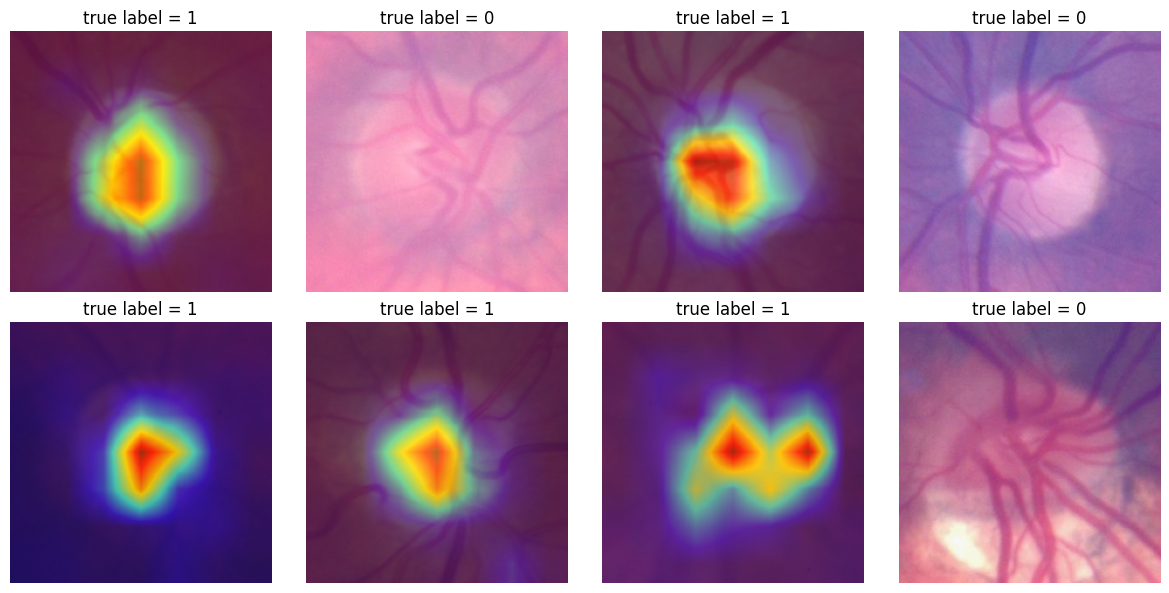

In [ ]:
!pip install -q grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
# Train (or reuse) a ResNet50 model on one dataset first, e.g.:
tr, va, te = split_source(df[df.dataset == 'ACRIMA'], SEED)
model, thr, _ = train_model('resnet50', tr, va, SEED)
model.eval()
cam = GradCAM(model=model, target_layers=[model.layer4[-1]])   # last conv block of ResNet50
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k, ax in enumerate(axes.ravel()):
    row = te.iloc[k]
    x, _ = FundusDS(te.iloc[[k]], eval_tf)[0]
    heat = cam(input_tensor=x.unsqueeze(0).to(DEVICE), targets=None)[0]  # ← fix here
    rgb = np.array(Image.open(row.path).convert('RGB').resize((IMG, IMG))) / 255.0
    ax.imshow(show_cam_on_image(rgb.astype('float32'), heat, use_rgb=True))
    ax.set_title(f'true label = {int(row.label)}'); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/gradcam.png', dpi=150); plt.show()

In [ ]:
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/glaucoma_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>